# Forces in Physics

An interactive exploration of fundamental force concepts — from Newton's laws to buoyancy — with live visualizations you can manipulate.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider, IntSlider
from matplotlib.patches import Rectangle, Arc
from mpl_toolkits.mplot3d import Axes3D
%matplotlib inline



## Newton's Second Law and Resultant Force

Every object near the Earth's surface experiences a **gravitational force** $\vec{F}_g = m\vec{g}$ directed downward. When an external force $\vec{F}_{\text{ext}}$ is applied, the **resultant** (net) force determines the object's acceleration via Newton's second law:

$$\vec{F}_{\text{net}} = \vec{F}_g + \vec{F}_{\text{ext}} = m\vec{a}$$

The resultant is simply the vector sum of all forces acting on the body. In the visualization below the gravitational pull is fixed at $5\,\text{N}$ downward; drag the sliders to apply an external force and watch the green resultant update in real time.


In [ ]:
@interact(
    Fx=FloatSlider(min=-10, max=10, step=0.5, value=3, description='F_ext X'),
    Fy=FloatSlider(min=-10, max=10, step=0.5, value=6, description='F_ext Y')
)
def plot_force(Fx, Fy):
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.add_patch(Rectangle((-1.5, -1.5), 3, 3, color='lightgrey', alpha=0.5))
    ax.quiver(0, 0, 0, -5, angles='xy', scale_units='xy', scale=1, color='b', width=0.02, label='Gravity (0, -5)')
    ax.quiver(0, 0, Fx, Fy, angles='xy', scale_units='xy', scale=1, color='r', width=0.02, label=f'External ({Fx:.1f}, {Fy:.1f})')
    Rx, Ry = Fx, Fy - 5
    ax.quiver(0, 0, Rx, Ry, angles='xy', scale_units='xy', scale=1, color='g', width=0.025, label=f'Resultant ({Rx:.1f}, {Ry:.1f})')
    ax.set_xlim(-10, 10)
    ax.set_ylim(-10, 10)
    ax.set_aspect('equal')
    ax.set_xlabel('X (N)')
    ax.set_ylabel('Y (N)')
    ax.set_title(f'|F_net| = {np.hypot(Rx, Ry):.2f} N')
    ax.legend(loc='upper left', fontsize=9)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


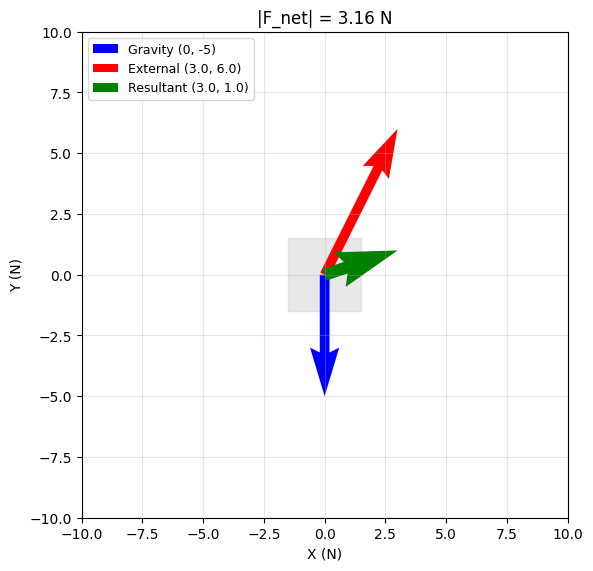

In [ ]:
# Hero figure — the one static image this notebook shows on GitHub.
plot_force(Fx=(FloatSlider(min=-10, max=10, step=0.5, value=3, description='F_ext X')).value, Fy=(FloatSlider(min=-10, max=10, step=0.5, value=6, description='F_ext Y')).value)


## Newton's Law of Universal Gravitation

Any two masses $m_1$ and $m_2$ separated by a distance $r$ attract each other with a force

$$F = G\,\frac{m_1\,m_2}{r^2}$$

where $G = 6.674 \times 10^{-11}\;\text{N m}^2\text{kg}^{-2}$ is the gravitational constant. The force is **attractive**, directed along the line joining the centres, and obeys Newton's third law: $\vec{F}_{12} = -\vec{F}_{21}$.

Key features:
- **Inverse-square law** — doubling the distance reduces the force by a factor of four.
- **Proportional to both masses** — heavier objects pull harder.

Below, two objects sit on the $x$-axis. Move the red mass and observe how the mutual gravitational arrows change magnitude ($G$ is scaled up for visibility).


In [ ]:
@interact(
    x2=FloatSlider(min=1, max=9, step=0.1, value=5, description='Object 2  x')
)
def plot_gravity(x2):
    m1, m2 = 10, 5
    G = 6.674e-1  # scaled for visualisation
    y = 5
    dist = abs(x2)
    F = G * m1 * m2 / dist**2

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.scatter(0, y, s=m1*20, color='blue', zorder=5)
    ax.scatter(x2, y, s=m2*20, color='red', zorder=5)
    ax.annotate(f'm₁={m1} kg', (0, y+0.4), ha='center', fontsize=9)
    ax.annotate(f'm₂={m2} kg', (x2, y+0.4), ha='center', fontsize=9)
    ax.quiver(0, y, F, 0, angles='xy', scale_units='xy', scale=1, color='blue', width=0.012, label=f'F on m₁ → {F:.2f} N')
    ax.quiver(x2, y, -F, 0, angles='xy', scale_units='xy', scale=1, color='red', width=0.012, label=f'F on m₂ → {F:.2f} N')
    ax.annotate(f'd = {dist:.2f}', xy=(x2/2, y-0.5), ha='center', fontsize=10, color='gray')
    ax.set_xlim(-1, 10)
    ax.set_ylim(3, 7)
    ax.set_xlabel('x')
    ax.set_title(f'Gravitational Force  F = {F:.3f} N')
    ax.legend(fontsize=8, loc='lower right')
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()



## Work Done by a Force

When a constant force $\vec{F}$ displaces an object by $\vec{d}$, the **work** done is the scalar

$$W = \vec{F}\cdot\vec{d} = |\vec{F}|\,|\vec{d}|\,\cos\theta$$

where $\theta$ is the angle between the two vectors.

| $\theta$ | $\cos\theta$ | Effect |
|---|---|---|
| $0°$ | $+1$ | Maximum positive work — force aids motion |
| $90°$ | $0$ | Zero work — force is perpendicular to motion |
| $180°$ | $-1$ | Maximum negative work — force opposes motion |

Adjust the force magnitude and angle below; the displacement vector is fixed at $5$ m along the positive $x$-axis.


In [ ]:
@interact(
    force=FloatSlider(min=0, max=10, step=0.5, value=5, description='|F| (N)'),
    angle=FloatSlider(min=0, max=360, step=5, value=30, description='θ (deg)')
)
def plot_work(force, angle):
    disp = 5
    angle_rad = np.deg2rad(angle)
    W = disp * force * np.cos(angle_rad)
    fx = force * np.cos(angle_rad)
    fy = force * np.sin(angle_rad)

    fig, ax = plt.subplots(figsize=(7, 5))
    ax.add_patch(Rectangle((-1.5, -1), 3, 2, color='lightgray', zorder=0))
    ax.arrow(0, 0, disp, 0, head_width=0.3, head_length=0.3, fc='b', ec='b', linewidth=1.5, label='Displacement d')
    if force > 0:
        ax.arrow(0, 0, fx, fy, head_width=0.3, head_length=0.3, fc='r', ec='r', linewidth=1.5, label='Force F')
    arc = Arc((0, 0), 2.5, 2.5, angle=0, theta1=0, theta2=angle, color='purple', linewidth=1.5)
    ax.add_patch(arc)
    ax.text(1.5*np.cos(angle_rad/2), 1.5*np.sin(angle_rad/2), f'{angle:.0f}°', fontsize=10, color='purple')
    ax.set_xlim(-6, 10)
    ax.set_ylim(-5, 5)
    ax.set_aspect('equal')
    ax.set_xlabel('X (m)')
    ax.set_ylabel('Y (m)')
    ax.set_title(f'W = |F|·|d|·cos θ = {force:.1f}×{disp}×cos({angle:.0f}°) = {W:.2f} J')
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()



## Torque (Moment of a Force)

Torque measures the tendency of a force to produce rotation about a point. For a force $\vec{F}$ applied at position $\vec{r}$ from the pivot:

$$\vec{\tau} = \vec{r} \times \vec{F}$$

Because it is a **cross product**, the torque vector is perpendicular to both $\vec{r}$ and $\vec{F}$; its direction follows the right-hand rule. The magnitude is $|\vec{\tau}| = |\vec{r}||\vec{F}|\sin\phi$, where $\phi$ is the angle between $\vec{r}$ and $\vec{F}$.

- If $\vec{F}$ is parallel to $\vec{r}$ ($\phi=0$), the torque is zero — the force pushes straight through the pivot.
- Maximum torque occurs when $\vec{F}$ is perpendicular to $\vec{r}$ ($\phi=90°$).

Below, the blue dot sits at a fixed position $(5,5,5)$. Adjust the three components of the applied force and see the resulting torque vector (green).


In [ ]:
@interact(
    Fx=FloatSlider(min=-10, max=10, step=0.5, value=1, description='Force X'),
    Fy=FloatSlider(min=-10, max=10, step=0.5, value=1, description='Force Y'),
    Fz=FloatSlider(min=-10, max=10, step=0.5, value=1, description='Force Z')
)
def plot_torque(Fx, Fy, Fz):
    pos = np.array([5, 5, 5])
    force = np.array([Fx, Fy, Fz])
    torque = np.cross(pos, force)

    fig = plt.figure(figsize=(7, 6))
    ax = fig.add_subplot(111, projection='3d')
    ax.quiver(0, 0, 0, *pos, color='k', linestyle='--', arrow_length_ratio=0.08, label='Position r')
    ax.scatter(*pos, color='blue', s=80)
    ax.quiver(*pos, *force, color='r', arrow_length_ratio=0.1, label=f'Force F = ({Fx},{Fy},{Fz})')
    ax.quiver(*pos, *torque, color='g', arrow_length_ratio=0.1, label=f'Torque τ = ({torque[0]:.1f},{torque[1]:.1f},{torque[2]:.1f})')
    ax.set_xlabel('X'); ax.set_ylabel('Y'); ax.set_zlabel('Z')
    ax.set_xlim(-10, 10); ax.set_ylim(-10, 10); ax.set_zlim(-10, 10)
    ax.set_title(f'|τ| = {np.linalg.norm(torque):.2f} N·m')
    ax.legend(fontsize=8, loc='upper left')
    plt.tight_layout()
    plt.show()



## Hydrostatic Pressure

In a static fluid of uniform density $\rho$, the pressure increases linearly with depth $h$ below the surface:

$$P = \rho\, g\, h$$

This comes from balancing the weight of the fluid column above a point against the pressure at that point. At the free surface ($h=0$) the gauge pressure is zero; at depth $h$ the fluid must support the weight $\rho g h$ per unit area above it.

Practical consequences:
- Pressure depends only on depth, **not** on the shape of the container (Pascal's law).
- For water ($\rho \approx 1000\;\text{kg/m}^3$) every additional metre of depth adds roughly $9\,810\;\text{Pa}$.


In [ ]:
@interact(
    depth=FloatSlider(min=0, max=10, step=0.2, value=3, description='Depth (m)')
)
def plot_pressure(depth):
    rho, g = 1000, 9.81
    P = rho * g * depth

    fig, ax = plt.subplots(figsize=(5, 6))
    ax.axhline(0, color='dodgerblue', linewidth=2, label='Water surface')
    ax.fill_between([0, 1], 0, -depth, color='lightskyblue', alpha=0.4)
    if depth > 0:
        ax.quiver(0.5, 0, 0, -depth, angles='xy', scale_units='xy', scale=1, color='red', width=0.015, label=f'h = {depth:.1f} m')
    ax.text(0.5, -depth/2, f'{depth:.1f} m', ha='center', va='center', fontsize=11, color='darkred')
    ax.set_xlim(0, 1); ax.set_ylim(-11, 2)
    ax.set_xlabel('Width (m)'); ax.set_ylabel('Depth (m)')
    ax.set_title(f'P = ρgh = {P:,.0f} Pa  ({P/1e3:.2f} kPa)')
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()



## Archimedes' Principle

A body submerged (fully or partially) in a fluid experiences an upward **buoyant force** equal to the weight of the fluid displaced:

$$F_b = \rho_{\text{fluid}}\; g\; V_{\text{submerged}}$$

- If $F_b < mg$, the object sinks further.
- If $F_b = mg$, the object floats in equilibrium.
- If $F_b > mg$ (e.g., a sealed air-filled container), the object is pushed upward.

The visualization shows a rectangular block ($0.2\;\text{m}$ wide, $2\;\text{m}$ tall) being submerged into water. The blue shaded region marks the submerged portion and the green arrow represents the buoyant force.


In [ ]:
@interact(
    depth=FloatSlider(min=0, max=3, step=0.1, value=1, description='Depth (m)')
)
def plot_archimedes(depth):
    rho_w, g = 1000, 9.81
    block_w, block_h = 0.2, 2
    submerged_h = min(depth, block_h)
    Fb = rho_w * g * block_w * submerged_h

    fig, ax = plt.subplots(figsize=(5, 6))
    ax.axhline(0, color='dodgerblue', linewidth=2)
    ax.fill_between([0, 1], 0, -3, color='lightskyblue', alpha=0.2)
    ax.add_patch(Rectangle((0.4, -depth), block_w, block_h, color='lightgray', ec='black'))
    ax.add_patch(Rectangle((0.4, -depth), block_w, submerged_h, color='steelblue', alpha=0.5))
    if Fb > 0:
        scale = Fb * 5e-4
        ax.quiver(0.5, -depth + block_h, 0, scale, angles='xy', scale_units='xy', scale=1, color='green', width=0.02, label=f'F_b = {Fb:.1f} N')
    ax.set_xlim(0, 1); ax.set_ylim(-3.5, 3)
    ax.set_xlabel('Width (m)'); ax.set_ylabel('Depth (m)')
    ax.set_title(f"Archimedes' Principle — Buoyant Force = {Fb:.1f} N")
    ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
